In [1]:
import ast
import pandas as pd
import matplotlib.pyplot as plt
import datasets as load_datasets

#Loading data
datasets = load_datasets.load_dataset('lukebarousse/data_jobs')
df = datasets['train'].to_pandas()

#Data cleaning
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else(x))

df_DA = df[df['job_title_short'] == 'Data Analyst']

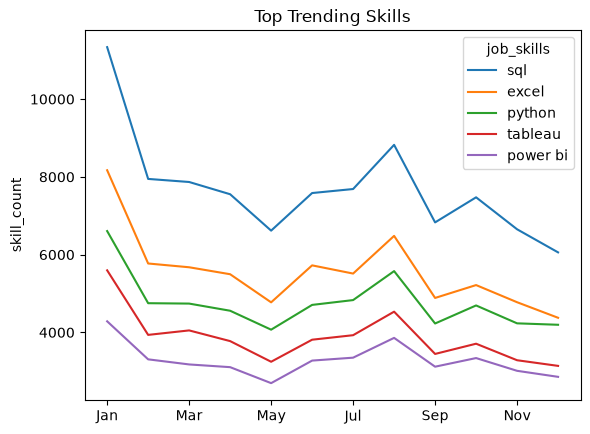

In [2]:
df_DA = df[df['job_title_short'] == 'Data Analyst']

df_DA['job_posted_month_no'] = df['job_posted_date'].dt.month

df_DA_explode = df_DA.explode('job_skills')

df_DA_pivot = df_DA_explode.pivot_table(index='job_posted_month_no', columns='job_skills', aggfunc='size', fill_value=0)

df_DA_pivot.loc['Total'] = df_DA_pivot.sum()
df_DA_pivot = df_DA_pivot[df_DA_pivot.loc['Total'].sort_values(ascending=False).index]

df_DA_pivot = df_DA_pivot.drop('Total')

df_DA_pivot = df_DA_pivot.reset_index()
df_DA_pivot['job_posted_month'] = df_DA_pivot['job_posted_month_no'].apply(lambda x: pd.to_datetime(x, format='%m').strftime('%b'))
df_DA_pivot = df_DA_pivot.set_index('job_posted_month')
df_DA_pivot = df_DA_pivot.drop(columns='job_posted_month_no')

df_DA_pivot.iloc[:, :5].plot(kind='line')
plt.title('Top Trending Skills')
plt.ylabel('skill_count')
plt.xlabel('')
plt.show()

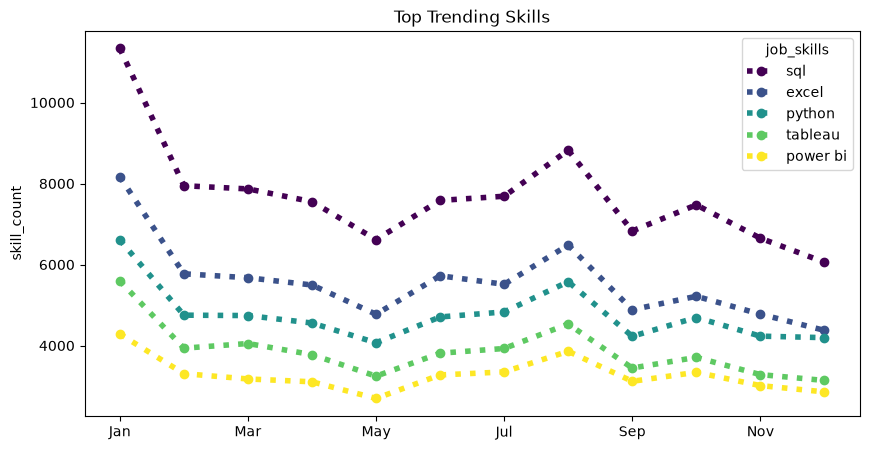

In [10]:
df_DA_pivot.iloc[:, :5].plot(
    kind='line',
    linewidth= 4, 
    linestyle=':',
    colormap='viridis',
    marker= 'o',
    figsize=(10, 5)
)
plt.title('Top Trending Skills')
plt.ylabel('skill_count')
plt.xlabel('')
plt.show()
plt.show()

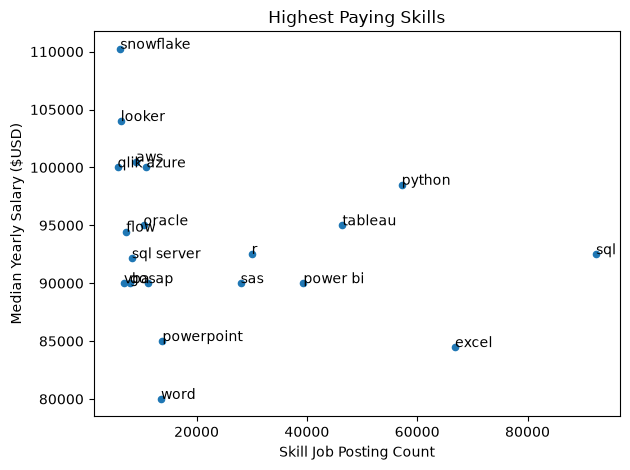

In [14]:
df = df[df['job_title_short'] == 'Data Analyst']
df_skills = df.explode('job_skills')
df_stats = df_skills.groupby('job_skills').agg(
    skill_count = ('job_skills', 'count'),
    median_salary = ('salary_year_avg', 'median')
)

top_skill = 20
df_stats = df_stats.sort_values(by='skill_count', ascending=False).head(top_skill)

df_stats.plot(kind='scatter', x='skill_count', y='median_salary')
plt.title('Highest Paying Skills')
plt.xlabel('Skill Job Posting Count')
plt.ylabel('Median Yearly Salary ($USD)')

for i, txt in enumerate(df_stats.index):
    plt.text(df_stats['skill_count'].iloc[i], df_stats['median_salary'].iloc[i], txt)

plt.tight_layout()
plt.show()

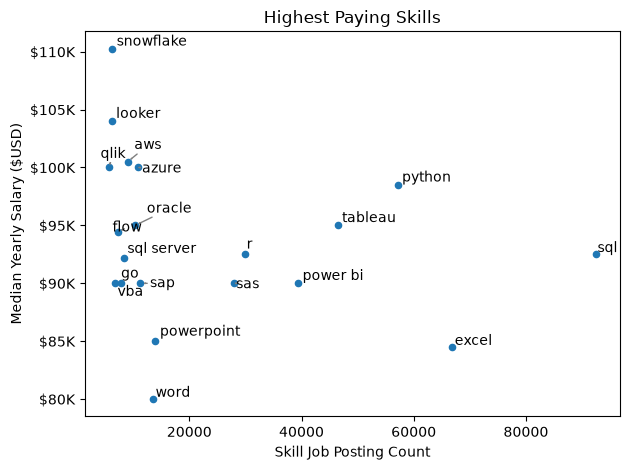

In [19]:
from adjustText import adjust_text

df_stats.plot(kind='scatter', x='skill_count', y='median_salary')
plt.title('Highest Paying Skills')
plt.xlabel('Skill Job Posting Count')
plt.ylabel('Median Yearly Salary ($USD)')

text=[]
for i, txt in enumerate(df_stats.index):
    text.append(plt.text(df_stats['skill_count'].iloc[i], df_stats['median_salary'].iloc[i], txt))

ax = plt.gca()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, pos: f'${int(y/1000)}K'))

adjust_text(text, arrowprops=dict(arrowstyle="->", color='grey', lw=1))

plt.tight_layout()
plt.show()